# Trabajando con estadísticas
Fecha: 20 junio 2025

## Importación del librerías

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Carga de datos

In [2]:
df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## Creación de figuras

Text(0, 0.5, 'Tip')

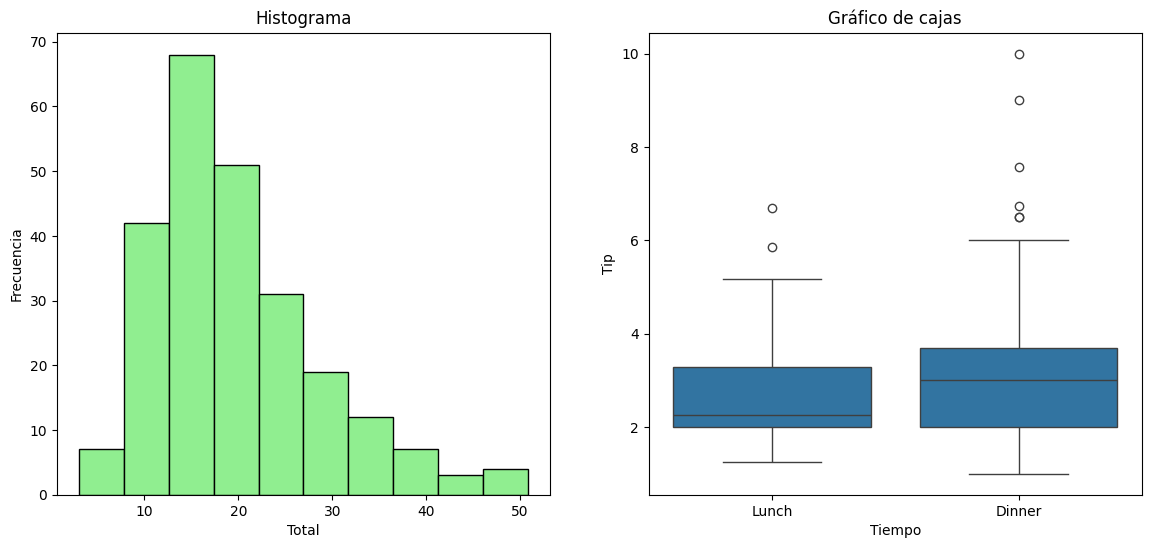

In [4]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.hist(
    df['total_bill'],
    bins=10,
    color='lightgreen',
    edgecolor='black'
)
plt.title("Histograma")
plt.xlabel("Total")
plt.ylabel("Frecuencia")

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='time', y='tip')
plt.title("Gráfico de cajas")
plt.xlabel("Tiempo")
plt.ylabel("Tip")

Los histogramas usualmente se hacen con valores reales, pues muestran la frecuencia de datos que caen en un rango de valores.

Desde un punto estadístico clásico, para un DataFrame, cada columna es un atributo o variable aleatorio. Por ejemplo, en el caso de `total_bill`, es una variable cuantitativa continua.

Recordar que hay dos tipos de variables cuantitativas:
- Discretas y continuas.

Por otro lado, hay que recordar que hay variables cualitativas tienen otros tipos de clasificaciones:
- Ordinal si siguen algún tipo de orden.
- Nominal si es una variable distintiva que no sigue un orden.

Un ejemplo de variable nominal en este DataFrame es el atributo `time`, que establece si el plato fue servido en el almuerzo o cena.

Si bien, almuerzo y cena siguen un patrón de tiempo; en el caso del dataset solo cumple con la función de catalogar. No establece un orden en los datos.

Una cosa muy importante antes de hacer el análisis de los datos es conocer el origen de estos. Es así como somos capaces de determinar más situaciones que puedan explicar cosas de los datos.

### Gráfico de cajas
Lo que ocurre con el gráfico de cajas es que para explorar datos. Se observan los cuartiles, y los rangos de valores que aún se consideran aceptables dentro de los cuartiles.

Más allá de eso, los valores fuera de esos rangos aceptados son considerados valores extremos, y pueden influir en medidas estadísticas a pesar de no ser valores que sean realmente comúnes.

Los diagramas de caja son muy útiles para mostrarnos la distribución de los datos. En caso de que los cuartiles y los rangos aceptables sean iguales, entonces la distribución es normal.

En caso de que la distribución sea asimétrica, desviada la media hacia la izquierda o hacia la derecha, entonces toca hacer procesos de normalización.

## Segunda carga de datos

In [6]:
second_df = sns.load_dataset('flights')
second_df.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [7]:
grouped_df = second_df.groupby('year').agg({'passengers':'sum'}).reset_index()
grouped_df

,year,passengers
0,1949,1520
1,1950,1676
2,1951,2042
3,1952,2364
4,1953,2700
5,1954,2867
6,1955,3408
7,1956,3939
8,1957,4421
9,1958,4572


In [10]:
grouped_df['income']=grouped_df['passengers']*np.random.uniform(20, 30)
grouped_df

,year,passengers,income
0,1949,1520,35621.539417
1,1950,1676,39277.434252
2,1951,2042,47854.725980
3,1952,2364,55400.867883
4,1953,2700,63275.102912
5,1954,2867,67188.785203
6,1955,3408,79867.241009
7,1956,3939,92311.344581
8,1957,4421,103607.122212
9,1958,4572,107145.840930


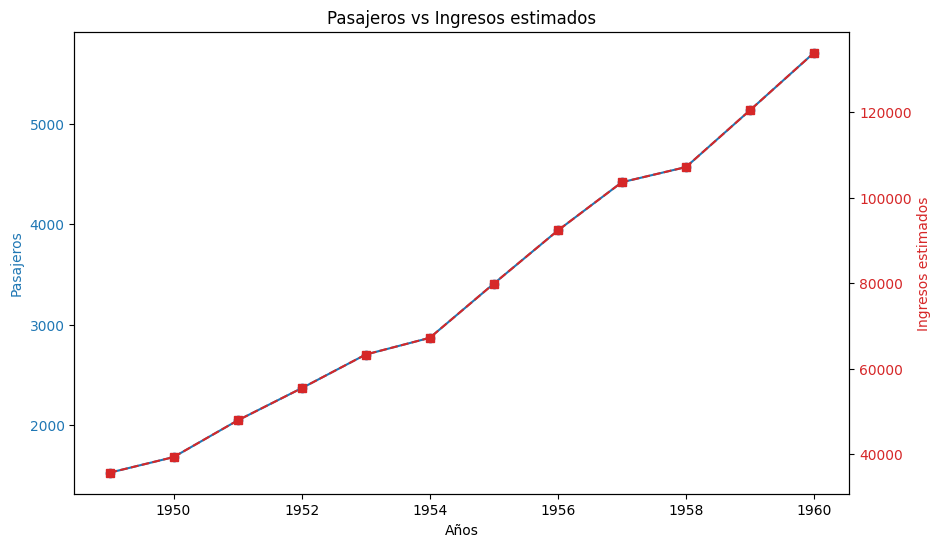

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))

color = 'tab:blue'
ax.set_xlabel('Años')
ax.set_ylabel('Pasajeros', color=color)
ax.plot(
    grouped_df['year'], 
    grouped_df['passengers'],
    color=color,
    marker='o',
    label='Pasajero')
ax.tick_params(axis='y', labelcolor=color)

new_ax = ax.twinx()
new_color = 'tab:red'
new_ax.set_ylabel('Ingresos estimados', color=new_color)
new_ax.plot(
    grouped_df['year'], 
    grouped_df['income'], 
    color=new_color, 
    linestyle='--', 
    marker='s', 
    label='Ingreso')
new_ax.tick_params(axis='y', labelcolor=new_color)

plt.title('Pasajeros vs Ingresos estimados')
plt.show()
